# Insurance Claim Fraud Detection — Full Pipeline

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

## 1. Load & Understand Data

In [2]:
df = pd.read_csv("../data/carclaims.csv")
print("Shape:", df.shape)
print("\nTarget distribution:")
print(df["FraudFound"].value_counts())
df.head(2)

Shape: (15420, 33)

Target distribution:
FraudFound
No     14497
Yes      923
Name: count, dtype: int64


,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,...,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange-Claim,NumberOfCars,Year,BasePolicy,FraudFound
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,...,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability,No
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,...,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision,No


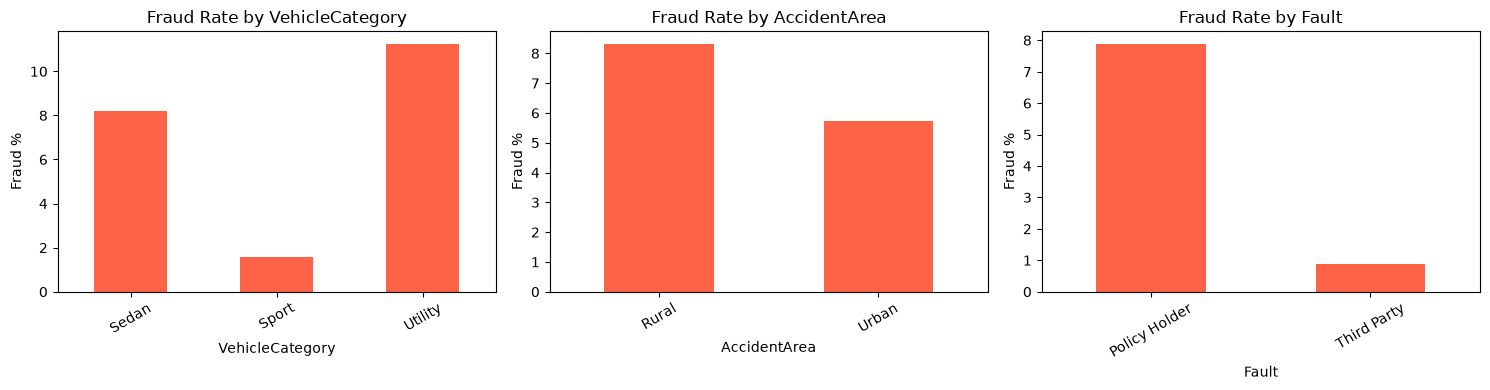

In [3]:
# Fraud rate by key features
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["VehicleCategory", "AccidentArea", "Fault"]):
    fraud_rate = df.groupby(col)["FraudFound"].apply(lambda x: (x == "Yes").mean() * 100)
    fraud_rate.plot(kind="bar", ax=ax, color="tomato")
    ax.set_title(f"Fraud Rate by {col}")
    ax.set_ylabel("Fraud %")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## 2. Feature Engineering

In [4]:
# Drop ID columns + separate target
y = df["FraudFound"].map({"Yes": 1, "No": 0})
X = df.drop(columns=["PolicyNumber", "RepNumber", "Year", "FraudFound"])

# Stratified split to preserve 6% fraud ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Fraud in train:", f"{y_train.mean()*100:.1f}%")
print("Fraud in test: ", f"{y_test.mean()*100:.1f}%")

Train: (12336, 29) | Test: (3084, 29)
Fraud in train: 6.0%
Fraud in test:  6.0%


In [5]:
# Auto-detect column types
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
print("Numerical:", num_cols)
print("Categorical:", cat_cols)

# Scale numbers, encode categories
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)
])

Numerical: ['WeekOfMonth', 'WeekOfMonthClaimed', 'Age', 'Deductible', 'DriverRating']
Categorical: ['Month', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'Sex', 'MaritalStatus', 'Fault', 'PolicyType', 'VehicleCategory', 'VehiclePrice', 'Days:Policy-Accident', 'Days:Policy-Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType', 'NumberOfSuppliments', 'AddressChange-Claim', 'NumberOfCars', 'BasePolicy']


## 3. Train Best Model — Random Forest

In [6]:
# Pipeline: preprocess → classify
# class_weight=balanced handles 6% fraud imbalance
# max_depth + min_samples_leaf prevent overfitting
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        class_weight="balanced",
        n_estimators=100,
        max_depth=10,
        min_samples_leaf=5,
        random_state=42
    ))
])

model.fit(X_train, y_train)
print("Training complete.")

Training complete.


## 4. Evaluate

In [7]:
THRESHOLD = 0.30  # lower threshold to catch more fraud

for split, X, y in [("TRAIN", X_train, y_train), ("TEST", X_test, y_test)]:
    prob = model.predict_proba(X)[:, 1]
    pred = (prob >= THRESHOLD).astype(int)
    r = classification_report(y, pred, target_names=["No Fraud", "Fraud"], output_dict=True, zero_division=0)
    auc = roc_auc_score(y, prob)
    print(f"{split} — Recall: {r['Fraud']['recall']:.2f} | F1: {r['Fraud']['f1-score']:.2f} | AUC: {auc:.4f}")

# Final test report
y_pred = (model.predict_proba(X_test)[:, 1] >= THRESHOLD).astype(int)
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["No Fraud", "Fraud"], zero_division=0))

TRAIN — Recall: 0.98 | F1: 0.23 | AUC: 0.9233
TEST — Recall: 0.97 | F1: 0.22 | AUC: 0.8152

Confusion Matrix:
[[1655 1244]
 [   5  180]]

Classification Report:
              precision    recall  f1-score   support

    No Fraud       1.00      0.57      0.73      2899
       Fraud       0.13      0.97      0.22       185

    accuracy                           0.60      3084
   macro avg       0.56      0.77      0.47      3084
weighted avg       0.94      0.60      0.70      3084



## 5. Save Model

In [8]:
joblib.dump(model, "../model/best_model_rf.pkl")
print("Model saved → model/best_model_rf.pkl")

Model saved → model/best_model_rf.pkl
